# RouteRanker – Module 3: Exploratory Data Analysis (EDA)
**Goal:** understand the feature-engineered dataset from Module 2 before any preprocessing or modelling – distributions, time-of-day patterns, route comparisons, geography, correlations and data quality.

> **Read this first.** GTFS contains *planned* service. Every number here is a count of **scheduled** trips, stops or timings. There are **no passenger counts or occupancy** in the data, so this notebook never calls a route overcrowded or underutilised. Routes that look different are *candidates for further investigation*, not conclusions.

Change `CITY` to analyse another city; the sentences printed under "Observations" are computed from the data, so they update automatically. `python run_module3.py` repeats the whole analysis for all 7 cities and writes the reports.

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src import eda
pd.set_option("display.max_columns", 40, "display.width", 200)
CITY = "bengaluru"    # ahmedabad, bengaluru, chennai, delhi, hyderabad, kochi, pune
R = eda.analyze(CITY)
rf, rh, su, h, p = R["rf"], R["rh"], R["su"], R["h"], R["p"]
print(f"{CITY}: {len(rf):,} routes, {len(su):,} stops, {len(rh):,} route-hour rows")

/home/claude/RouteRanker/src/eda.py:281: RuntimeWarning: invalid value encountered in divide
  J = inter / (size[:, None] + size[None, :] - inter)


bengaluru: 4,416 routes, 9,948 stops, 31,799 route-hour rows


## 1–2. Loading and inspecting the dataset

In [2]:
print("shape (rows, columns):", rf.shape)
rf.head(3)

shape (rows, columns): (4416, 48)


,city,route_id,route_name,route_type,n_trips,median_stops_per_trip,avg_trip_duration_min,median_trip_duration_min,n_service_ids,trips_from_frequency,has_time_backwards_trip,first_departure_h,last_departure_h,n_directions,service_span_h,n_active_hours,peak_hour,peak_hour_trips,trips_per_active_hour,trips_morning,...,trips_friday,trips_saturday,trips_sunday,avg_trips_per_weekday,avg_trips_per_weekend_day,weekend_to_weekday_ratio,length_km_stops,length_km_shape,length_km,length_method,n_unique_stops,stops_per_km,avg_speed_kmh,speed_implausible,overlap_partner,max_stop_overlap,overlap_share_of_route,overlap_partner_name,mean_routes_per_stop,sparse_schedule
0,bengaluru,1000,KBS-3C,3,87,40.0,98.669349,99.983333,1,0,False,4.916667,23.750000,2,18.833333,20,15,13,4.350000,27,...,87,87,87,87.0,87.0,1.0,26.886204,28.831333,28.831333,shapes.txt,77,2.670706,17.301683,False,4866,0.885057,1.000,359,185.779221,False
1,bengaluru,1001,D2-SNBS,3,172,2.0,4.639535,5.000000,1,0,False,5.416667,22.966667,2,17.550000,18,13,19,9.555556,57,...,172,172,172,172.0,172.0,1.0,0.260343,0.624458,0.624458,shapes.txt,2,3.202776,7.493498,False,994,0.333333,0.500,D3-SNBS,76.000000,False
2,bengaluru,1002,333-C,3,6,20.0,59.161111,60.000000,1,0,False,6.000000,18.583333,2,12.583333,5,6,2,1.200000,4,...,6,6,6,6.0,6.0,1.0,14.758830,16.702210,16.702210,shapes.txt,40,2.394893,16.702210,False,9569,0.860465,0.925,335 KBS-HAL ARDC,198.225000,False


In [3]:
rf.tail(3)

,city,route_id,route_name,route_type,n_trips,median_stops_per_trip,avg_trip_duration_min,median_trip_duration_min,n_service_ids,trips_from_frequency,has_time_backwards_trip,first_departure_h,last_departure_h,n_directions,service_span_h,n_active_hours,peak_hour,peak_hour_trips,trips_per_active_hour,trips_morning,...,trips_friday,trips_saturday,trips_sunday,avg_trips_per_weekday,avg_trips_per_weekend_day,weekend_to_weekday_ratio,length_km_stops,length_km_shape,length_km,length_method,n_unique_stops,stops_per_km,avg_speed_kmh,speed_implausible,overlap_partner,max_stop_overlap,overlap_share_of_route,overlap_partner_name,mean_routes_per_stop,sparse_schedule
4413,bengaluru,997,365,3,104,42.0,85.667147,90.0,1,0,False,4.25,21.666667,2,17.416667,18,10,11,5.777778,41,...,104,104,104,104.0,104.0,1.0,22.271808,24.259428,24.259428,shapes.txt,81,3.338908,16.172952,False,2027,0.975610,0.987654,V-365,141.925926,False
4414,bengaluru,998,150,3,109,7.0,24.311927,25.0,1,0,False,5.50,21.833333,2,16.333333,17,20,9,6.411765,40,...,109,109,109,109.0,109.0,1.0,4.245030,4.906316,4.906316,shapes.txt,14,2.853465,11.775159,False,7734,0.521739,0.857143,154,203.785714,False
4415,bengaluru,999,13-C,3,36,28.0,70.275463,70.0,1,0,False,6.00,22.500000,2,16.500000,16,11,4,2.250000,16,...,36,36,36,36.0,36.0,1.0,13.073608,15.739212,15.739212,shapes.txt,54,3.430922,13.490753,False,1161,0.847458,0.925926,13-A,63.777778,False


In [4]:
info, meta = R["info"]
print(meta)
info

{'rows': 4416, 'columns': 48, 'duplicate_rows': 0, 'duplicate_route_id': 0}


,dtype,non_null,missing,missing_%,unique
city,str,4416,0,0.0,1
route_id,str,4416,0,0.0,4416
route_name,str,4416,0,0.0,4416
route_type,int64,4416,0,0.0,1
n_trips,int64,4416,0,0.0,192
median_stops_per_trip,float64,4416,0,0.0,158
avg_trip_duration_min,float64,4416,0,0.0,1958
median_trip_duration_min,float64,4416,0,0.0,369
n_service_ids,int64,4416,0,0.0,1
trips_from_frequency,int64,4416,0,0.0,1


`dtypes`/non-null counts above show that identifiers (`route_id`, `route_name`) are text and the measurements are numbers. Missing values are *undefined*, never replaced by zero.

In [5]:
eda.describe(rf)

,count,min,median,mean,std,max,p90
n_trips,4416.0,1.00,3.00,13.10,32.72,398.00,28.50
n_unique_stops,4416.0,2.00,44.00,47.59,33.04,184.00,94.00
length_km,4416.0,0.01,19.79,24.45,32.42,688.78,40.00
service_span_h,4416.0,0.00,8.67,7.96,6.22,23.77,15.83
median_headway_min,3373.0,1.00,90.00,181.31,211.27,1000.00,530.00
avg_trip_duration_min,4416.0,0.90,65.75,66.39,36.16,660.00,108.36
trips_per_active_hour,4416.0,1.00,1.00,1.57,1.65,20.95,2.40
stops_per_km,4416.0,0.04,2.38,2.27,1.08,10.00,3.53
avg_speed_kmh,4416.0,0.03,18.56,47.40,332.45,8265.37,26.51
max_stop_overlap,4416.0,0.00,0.71,0.66,0.23,1.00,0.93


In [6]:
print("missing values per column (only columns with missing values):")
display(rf.isna().sum()[rf.isna().sum() > 0].to_frame("missing"))
print("duplicate rows:", rf.duplicated().sum(), "| duplicate route_id:", rf.route_id.duplicated().sum())

missing values per column (only columns with missing values):


,missing
median_headway_min,1043
overlap_partner,16
overlap_partner_name,16


duplicate rows: 0 | duplicate route_id: 0


**Unusual values / suitability:** `median_headway_min` is missing for routes with a single departure time (undefined, not zero); `overlap_partner` is missing when no other route shares a stop. No duplicate routes exist. The dataset is suitable for exploratory analysis, with the caveats in section 10.

In [7]:
for x in eda.timing_caveats(rf): print("CAVEAT:", x)
if not eda.timing_caveats(rf): print("No feed-level timing caveat detected for this city.")

No feed-level timing caveat detected for this city.


## 3. Univariate analysis

In [8]:
for _l in eda.obs_univariate(rf):
    print('•', _l)

• 4,416 routes in the dataset. Scheduled trips per route: median 3, mean 13.1, maximum 398 (133 times the median). 66% of routes have 5 or fewer scheduled trips and 7% have 50 or more, so service levels differ widely between routes.
• Distinct stops per route: median 44 (range 2-184).
• Estimated route length: median 19.8 km (middle half of routes 11.8-30.8 km). 99% of lengths come from shapes.txt; the rest are straight-line stop-to-stop distances, which understate road length.
• Scheduled service span (first to last departure): median 8.7 h; 32% of routes span 12 hours or more.
• Operating days: 100% of routes have the same number of scheduled trips on weekend days as on weekdays according to calendar.txt.


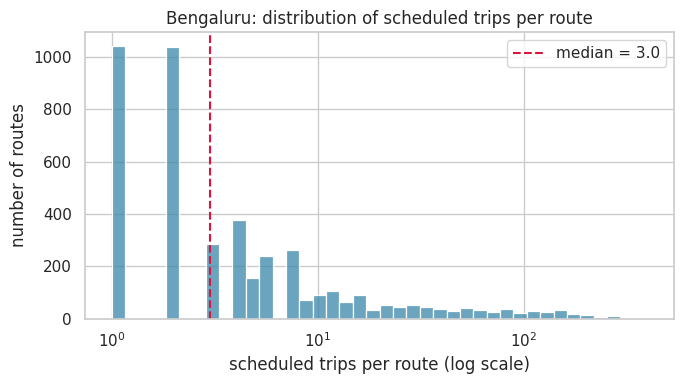

In [9]:
eda.f_hist(rf, 'n_trips', CITY, log_x=True); plt.show()

**What it shows:** how many routes have each number of scheduled trips (log scale, because a few routes have far more trips than most). A long right tail means service levels differ strongly between routes; the dashed line is the median.

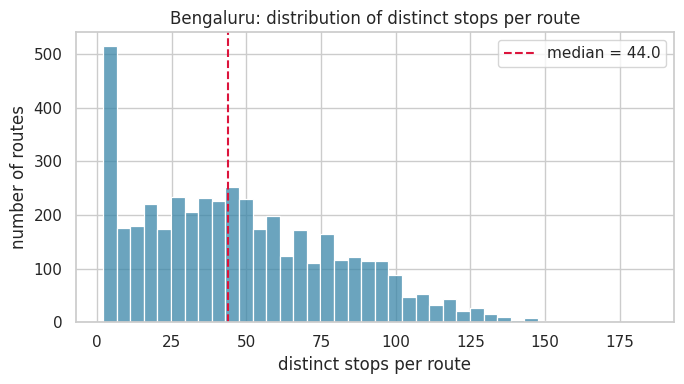

In [10]:
eda.f_hist(rf, 'n_unique_stops', CITY); plt.show()

**What it shows:** the spread of distinct stops per route – whether routes are broadly similar in size or differ a lot.

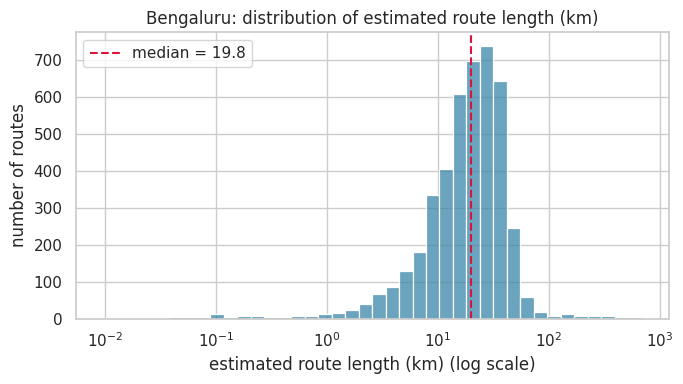

In [11]:
eda.f_hist(rf, 'length_km', CITY, log_x=True); plt.show()

**What it shows:** estimated route length. It comes from `shapes.txt` where the feed has it, otherwise from straight-line distances between stops (an understatement of road length).

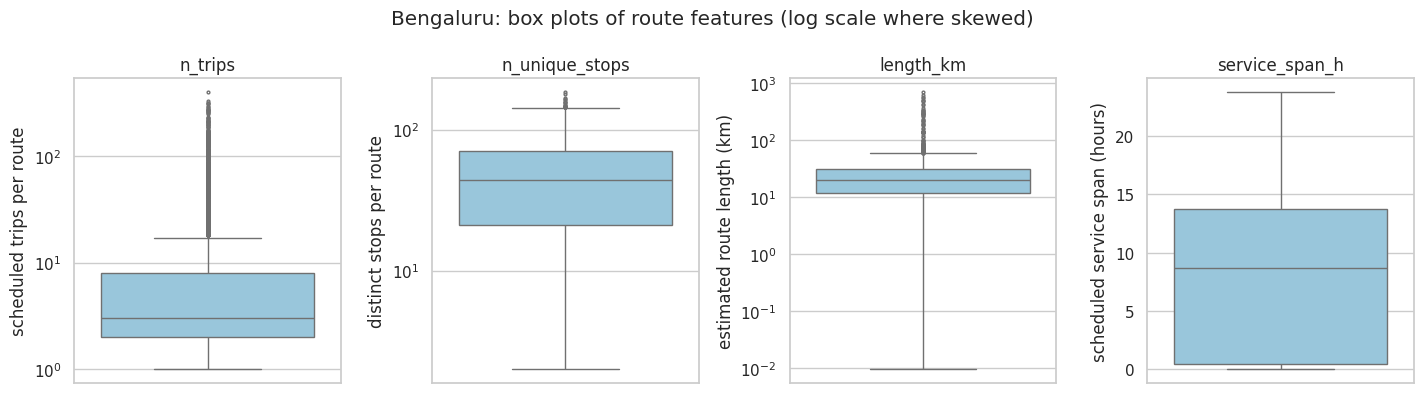

In [12]:
eda.f_box_panel(rf, CITY); plt.show()

**What it shows:** box = middle 50% of routes, line = median, dots = statistical outliers. Outliers are examined in section 9 – not removed.

In [13]:
rf.length_method.value_counts().to_frame('routes')

,routes
length_method,
shapes.txt,4372
stop coordinates (shape failed sanity check),44


## 4. Scheduled service by time of day
Time periods: **morning** 05:00–11:59 · **afternoon** 12:00–16:59 · **evening** 17:00–20:59 · **night** 21:00–04:59 (by first departure). An hour with no scheduled start has a genuine count of 0.

In [14]:
for _l in eda.obs_hourly(h, p):
    print('•', _l)

• Hours with the most scheduled trip starts: 08:00 (4,504), 07:00 (4,115), 15:00 (4,029). Hours with the fewest: 02:00 (31), 00:00 (43), 01:00 (44).
• By period: morning 42.3% of scheduled trips (3,491 per hour); afternoon 31.5% of scheduled trips (3,638 per hour); evening 21.0% of scheduled trips (3,038 per hour); night 5.3% of scheduled trips (382 per hour). The busiest period per hour is afternoon and the quietest is night. These are planned services, not passenger numbers; strong concentration in a few hours can also reflect how the publisher compiled the timetable, so it should be checked with the operator before it is read as a real service pattern.
• Weekday vs weekend: scheduled trips on a typical weekday (Wednesday services) 57,836; on Sunday 57,836 (100% of the weekday level). The calendar describes identical service on both days.


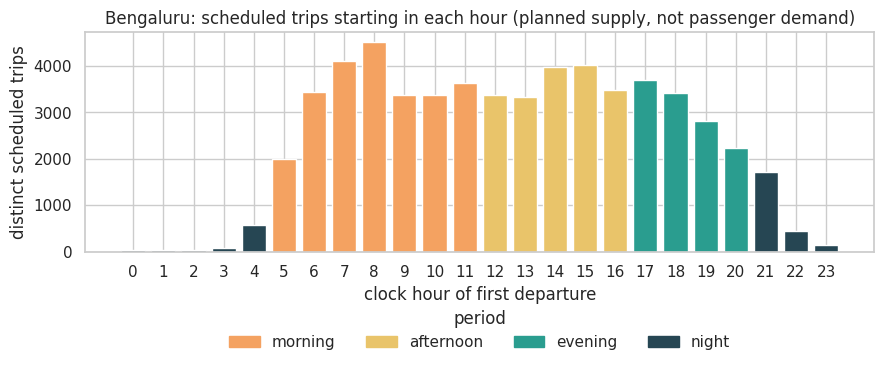

In [15]:
eda.f_hourly(h, CITY); plt.show()

**What it shows:** the number of distinct scheduled trips that *start* in each clock hour. Tall bars = hours in which the timetable offers many departures. This is planned supply, not passenger demand.

,hours,scheduled_trips,share_%,trips_per_hour
period,,,,
morning,7,24438,42.3,3491.0
afternoon,5,18191,31.5,3638.0
evening,4,12152,21.0,3038.0
night,8,3055,5.3,382.0


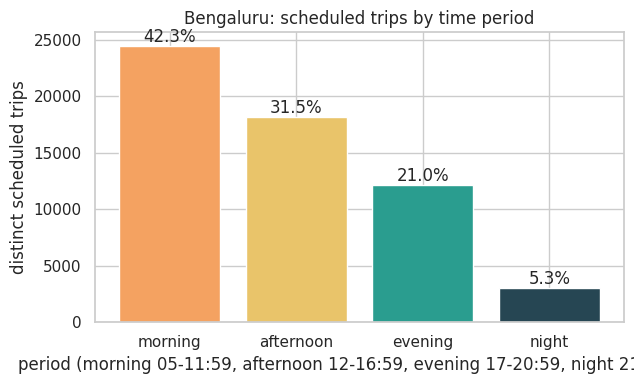

In [16]:
display(p); eda.f_period(p, CITY); plt.show()

**What it shows:** each period's share of all scheduled trips. Periods differ in length, so the `trips_per_hour` column is the fairer comparison.

In [17]:
if "trips_weekday_wed" in h and h.trips_weekday_wed.sum() != h.trips_sunday.sum():
    eda.f_weekday_sunday(h, CITY); plt.show()
else:
    print("Weekday and Sunday schedules are identical according to calendar.txt (or the calendar is missing) - no separate chart is meaningful.")

Weekday and Sunday schedules are identical according to calendar.txt (or the calendar is missing) - no separate chart is meaningful.


In [18]:
h[['scheduled_trips','scheduled_stop_visits','routes_with_trip_start','period']]

,scheduled_trips,scheduled_stop_visits,routes_with_trip_start,period
hour,,,,
0,43,472,23,night
1,44,1135,21,night
2,31,1186,14,night
3,72,1766,45,night
4,583,9685,331,night
5,1998,44118,1027,morning
6,3448,78255,1449,morning
7,4115,94255,1690,morning
8,4504,112327,1760,morning


## 5. Route-wise comparison

In [19]:
for _l in eda.obs_routes(rf, R['groups']):
    print('•', _l)

• Routes in the lowest quarter of scheduled trips (<= 1) have a median of 29 stops and 18.3 km; routes in the highest quarter (>= 18 trips) have 52 stops and 18.4 km.
• Median service span: 0.0 h (low-trip group) vs 15.0 h (high-trip group). A route with a single trip has a span of 0 by definition, so this difference is partly built in. It describes what the schedule looks like - not whether a route is efficient.
• Most stops on one route: 399-F D27G-ANK-HSK (184), 256-MB (178), 398-H D27G-HSK (166). Most scheduled trips: 375-D (398), 401-M (328), 378 (318).


In [20]:
R['groups']

,routes,n_trips,n_unique_stops,length_km,service_span_h,median_headway_min,avg_speed_kmh,max_stop_overlap
group,,,,,,,,
low (<= Q1),2082,1.0,29.0,18.28,0.00,450.0,18.86,0.56
middle,1156,4.0,66.0,25.87,10.38,110.0,19.15,0.81
high (>= Q3),1178,18.0,52.0,18.44,15.00,30.0,17.39,0.79


Routes are grouped by their number of scheduled trips (lowest quarter / middle / highest quarter) and the median of other features is compared. Differences describe the schedule; they do not prove inefficiency.

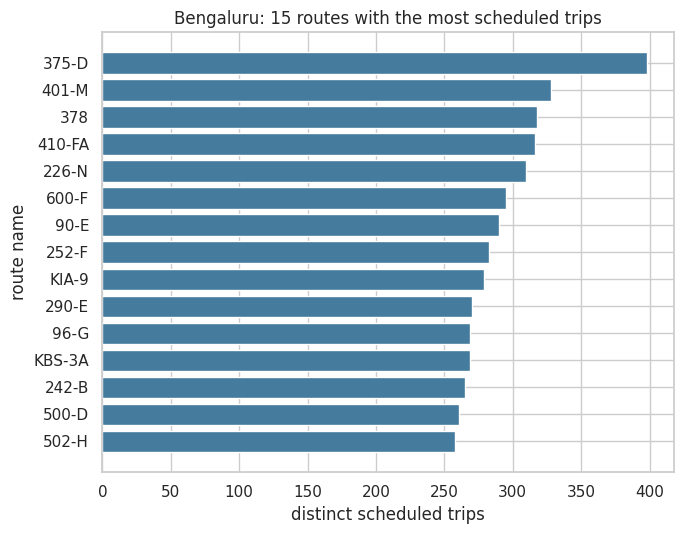

In [21]:
eda.f_top_routes(rf, CITY); plt.show()

In [22]:
rf.nlargest(10, 'n_trips')[['route_name','n_trips','n_unique_stops','length_km','service_span_h','median_headway_min']]

,route_name,n_trips,n_unique_stops,length_km,service_span_h,median_headway_min
392,375-D,398,44,12.566257,18.000000,5.0
61,401-M,328,75,23.671940,18.750000,5.0
69,378,318,115,30.779791,17.583333,5.0
436,410-FA,316,62,21.012759,17.333333,5.0
91,226-N,310,85,31.175042,19.916667,5.0
344,600-F,295,77,29.211388,18.916667,5.0
1396,90-E,290,22,6.876301,18.916667,5.0
415,252-F,283,53,14.228199,19.500000,5.0
70,KIA-9,279,48,37.344055,23.750000,5.0
219,290-E,270,79,22.291365,17.833333,5.0


In [23]:
R['low'].head(10)

,route_name,n_trips,n_unique_stops,length_km,service_span_h,trips_morning,trips_afternoon,trips_evening,trips_night
3386,KLN-80FTRD,1,3,0.317008,0.0,1,0,0,0
3784,J9THB-SGH,1,3,0.947564,0.0,0,0,0,1
4050,61-J CLO-CLO1,1,2,1.022396,0.0,1,0,0,0
3845,D35G-BSKL,1,2,1.113126,0.0,0,0,1,0
3370,253-J MLS-BNM,1,3,1.127236,0.0,1,0,0,0
1045,D24G-KRPGH,1,2,1.203316,0.0,0,0,1,0
1529,96-G SNB-BSN,1,2,1.316468,0.0,0,0,0,1
1900,PTH-MAS,1,3,1.327824,0.0,0,1,0,0
3160,RZP-D52G,1,3,1.374400,0.0,1,0,0,0
3779,KRMTTMC-ATO,1,4,1.473314,0.0,1,0,0,0


**Further information needed for stronger conclusions:** ridership/boardings per route and time period (matched to GTFS route ids and dates), vehicle capacity and fleet allocation, measured run times, operating costs, and the operator's purpose for each route (feeder, express, coverage).

## 6. Geographical analysis and route density

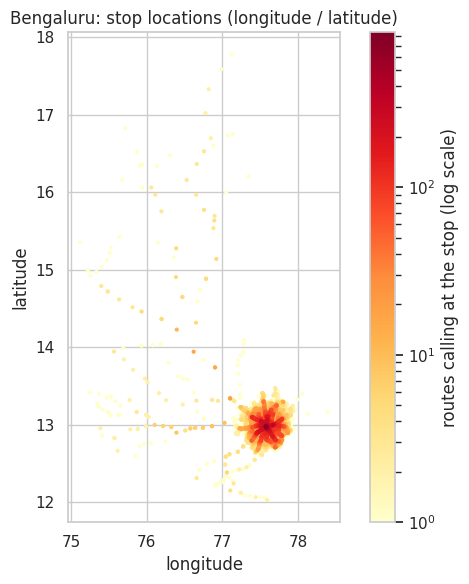

interactive heat map saved: reports/maps/bengaluru_stops_heatmap.html


In [24]:
eda.f_stop_scatter(su, CITY); plt.show()
os.makedirs("reports/maps", exist_ok=True)
eda.stop_map(su, CITY, f"reports/maps/{CITY}_stops_heatmap.html")
print("interactive heat map saved: reports/maps/%s_stops_heatmap.html" % CITY)

**What it shows:** every stop with valid coordinates, coloured by how many routes call there. Dense, dark areas are where many routes are timetabled to stop. It shows network structure, not where passengers are.

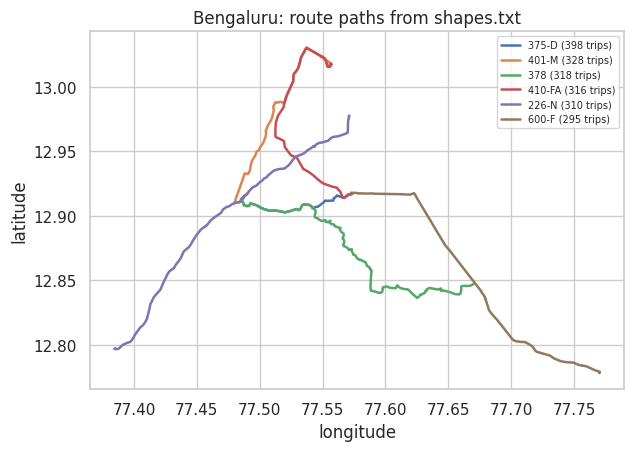

In [25]:
if R["shapes"] is not None:
    top = rf[rf.length_method == "shapes.txt"].nlargest(6, "n_trips")
    routes = [(r.route_id, f"{r.route_name} ({r.n_trips} trips)") for r in top.itertuples()]
    eda.f_shapes_static(R["shapes"], R["trip_shape"], routes, CITY); plt.show()
    eda.draw_routes_map(R["shapes"], R["trip_shape"], routes, f"reports/maps/{CITY}_top_route_shapes.html")
else:
    print("No usable shapes.txt for bus routes in this feed -> route paths are NOT drawn (no unsupported map is created).")

**How overlap is identified.** *Stop-based:* for each route, the Jaccard similarity (shared stops ÷ all stops) with every other route; routes with the same name and opposite-direction twins are excluded. *Path-based* (only where `shapes.txt` exists): each route's shape is turned into ~200 m grid cells and the Jaccard similarity of the cell sets is computed. Two routes sharing stops or a corridor are **not necessarily redundant** – they may serve different passengers, and these data say nothing about traffic.

In [26]:
for _l in eda.obs_overlap(rf, R['ov'], R['shape_ov']):
    print('•', _l)

• Stop-based overlap (Jaccard similarity of the stop sets of two routes): 1631 routes have a partner with >= 80% similar stops, 3239 with >= 50% (1043 distinct pairs at >= 80%). Same-name routes and opposite-direction twins are excluded. Sharing stops does not prove that two routes are redundant.
• Path-based overlap from shapes.txt (~200 m grid cells): 1628 routes share >= 80% of their corridor with another route, 3712 share >= 50%.


In [27]:
R['ov'].head(10)

,route_name,overlap_partner_name,max_stop_overlap,n_trips,partner_trips,length_km
19,KBS-1K,333-E,1.0,147,8,27.099252
11,335-E,KBS-1I,1.0,4,129,30.189982
10,342-F,V-342F,1.0,107,55,31.564874
1149,STJHS-4,STJHS-1,1.0,2,2,5.123811
1033,300-MV,V-300MV,1.0,227,167,11.949845
3328,D10-D10GATE,D10-D10GT,1.0,72,105,0.110900
851,304-H,304-X,1.0,4,3,38.564664
3612,NLS-3,NLS-2,1.0,2,1,8.152210
186,D12-BSN,D12G-D12,1.0,62,59,0.217033
203,402-B,402-D,1.0,149,2,20.410048


,route_id,shape_overlap_partner,shape_overlap_jaccard,shape_overlap_partner_name
2745,6845,2895,1.0,D47-KMSD
4413,997,2027,1.0,V-365
1703,4030,9542,1.0,285-MA DBP-VSD-KBS
65,1096,1173,1.0,285-M
66,1097,1014,1.0,335-E
2494,6081,9344,1.0,258-C SNBS-NMG
4139,9344,6081,1.0,258 SNBS-NMG
531,1819,4362,1.0,215 KBS-D44G


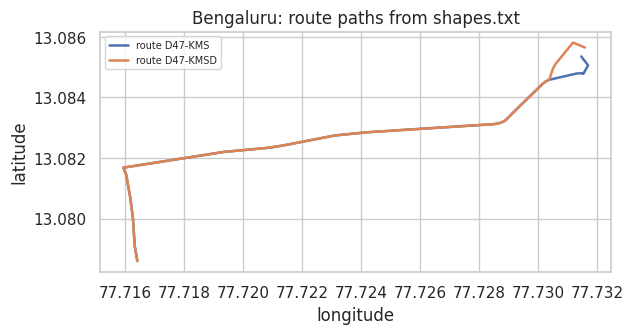

In [28]:
so = R["shape_ov"]
if so is not None:
    display(so.sort_values("shape_overlap_jaccard", ascending=False).head(8))
    best = so.sort_values("shape_overlap_jaccard", ascending=False).iloc[0]
    nm = rf.set_index("route_id").route_name
    eda.f_shapes_static(R["shapes"], R["trip_shape"], [(best.route_id, f"route {nm[best.route_id]}"), (best.shape_overlap_partner, f"route {nm[best.shape_overlap_partner]}")], CITY); plt.show()
else:
    print("Path-based overlap not available for this city (no shapes).")

## 7. Potentially overlapping or low-service routes – candidates for further investigation

In [29]:
print("route pairs sharing >= 80% of stops:", len(R["ov"]))
print("routes with very few scheduled trips (lowest 10%):", len(R["low"]), "| with fewer than 3:", int((rf.n_trips < 3).sum()))
rf[rf.n_trips < 3][["route_name","n_trips","n_unique_stops","length_km","service_span_h"]].head(8)

route pairs sharing >= 80% of stops: 1043
routes with very few scheduled trips (lowest 10%): 1043 | with fewer than 3: 2082


,route_name,n_trips,n_unique_stops,length_km,service_span_h
24,335-E SNBS-KDG,2,42,25.703512,0.416667
27,SNBS-CORP-KMT,2,6,3.023473,7.750000
39,KVASC-01,2,2,5.375786,7.666667
40,43-H ASP-PLO,1,16,8.782518,0.000000
41,KVS-SBS,2,6,2.783662,0.083333
48,356-CW Fly,1,16,13.735594,0.000000
52,MBS-17,1,37,28.369537,0.000000
55,285 SRN-KBS-GKVK,2,56,22.322480,8.666667


These lists are **observations to follow up**, not findings. A route with few trips may be a feeder, school or peak-only service; overlapping routes may serve different passengers. Reliable ridership and operational information is required before calling any route underutilised or suitable for merging.

## 8. Statistical analysis and correlation

In [30]:
for _l in eda.obs_corr(rf):
    print('•', _l)

• length_km vs n_trips: Spearman rho = 0.04 -> almost no association (the two vary almost independently).
• n_unique_stops vs n_trips: Spearman rho = 0.33 -> a weak association (longer/larger routes tend to have higher values of both).
• length_km vs n_unique_stops: Spearman rho = 0.75 -> a strong association (longer/larger routes tend to have higher values of both).
• length_km vs median_headway_min: Spearman rho = 0.09 -> almost no association (the two vary almost independently).


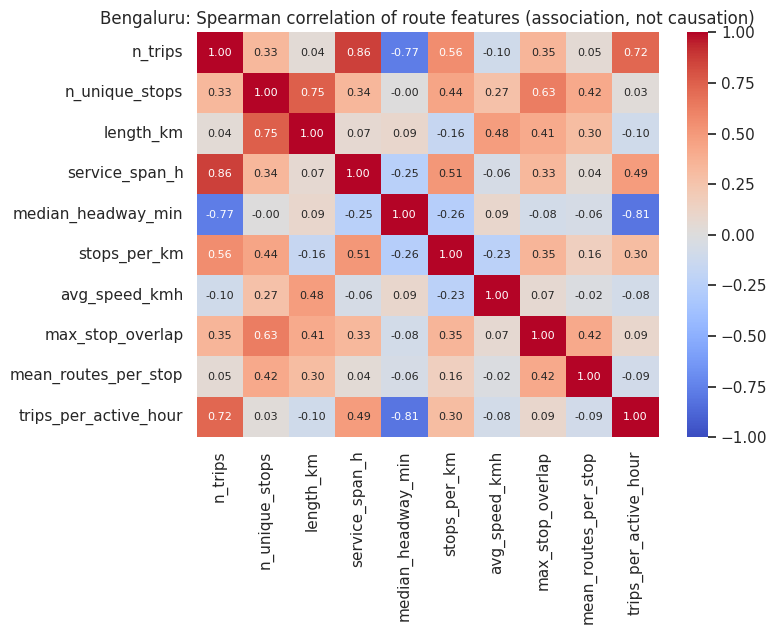

In [31]:
eda.f_corr(rf, CITY); plt.show()

**What it shows:** Spearman correlation (rank-based, robust to the skew in trip counts) between numeric features; identifiers are excluded. +1 = rise together, −1 = one rises as the other falls, 0 = no consistent link. Several pairs (scheduled trips, trips per active hour, headway, service span) are linked **by definition**, so their strong correlation is expected and is not a finding. Correlation is association, not causation.

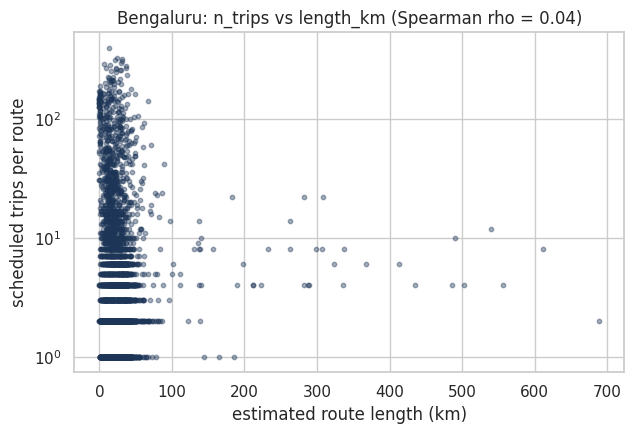

In [32]:
eda.f_scatter(rf, 'length_km', 'n_trips', CITY); plt.show()

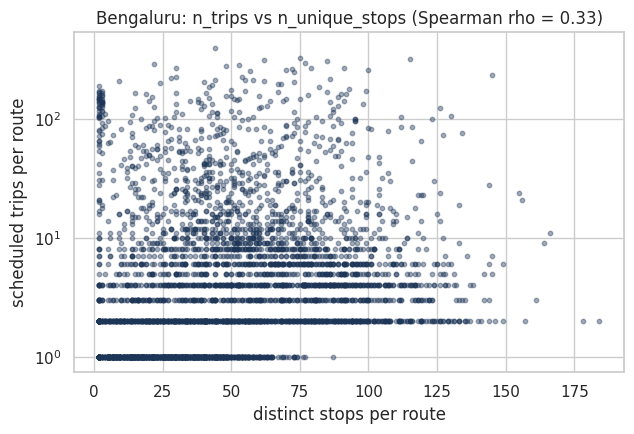

In [33]:
eda.f_scatter(rf, 'n_unique_stops', 'n_trips', CITY); plt.show()

## 9. Data quality and outlier analysis

In [34]:
R['out']

,feature,min,median,max,n_low_outliers,n_high_outliers,outliers_pct
0,n_trips,1.00,3.00,398.00,0,312,7.1
1,n_unique_stops,2.00,44.00,184.00,389,0,8.8
2,length_km,0.01,19.79,688.78,140,42,4.1
3,service_span_h,0.00,8.67,23.77,0,0,0.0
4,median_headway_min,1.00,90.00,1000.00,0,0,0.0
5,avg_speed_kmh,0.03,18.56,8265.37,88,231,7.2


Tukey fences (1.5 × IQR; on a log scale for skewed features) mark *statistical* outliers. They are investigated below, **not deleted**.

In [35]:
R['inv']

,check,routes,pct,reading
0,scheduled speed < 3 or > 80 km/h,92,2.1,"suspect: length, duration or both look wrong f..."
1,very long routes (> Q3 + 3 IQR),50,1.1,12 of them have a plausible scheduled speed ->...
2,very many scheduled trips (> Q3 + 3 IQR),460,10.4,0 combine several service patterns (counts add...
3,routes with fewer than 3 scheduled trips,2082,47.1,valid but sparse; headway undefined for many; ...
4,missing median headway (single departure time),1043,23.6,"undefined, not zero; kept missing"


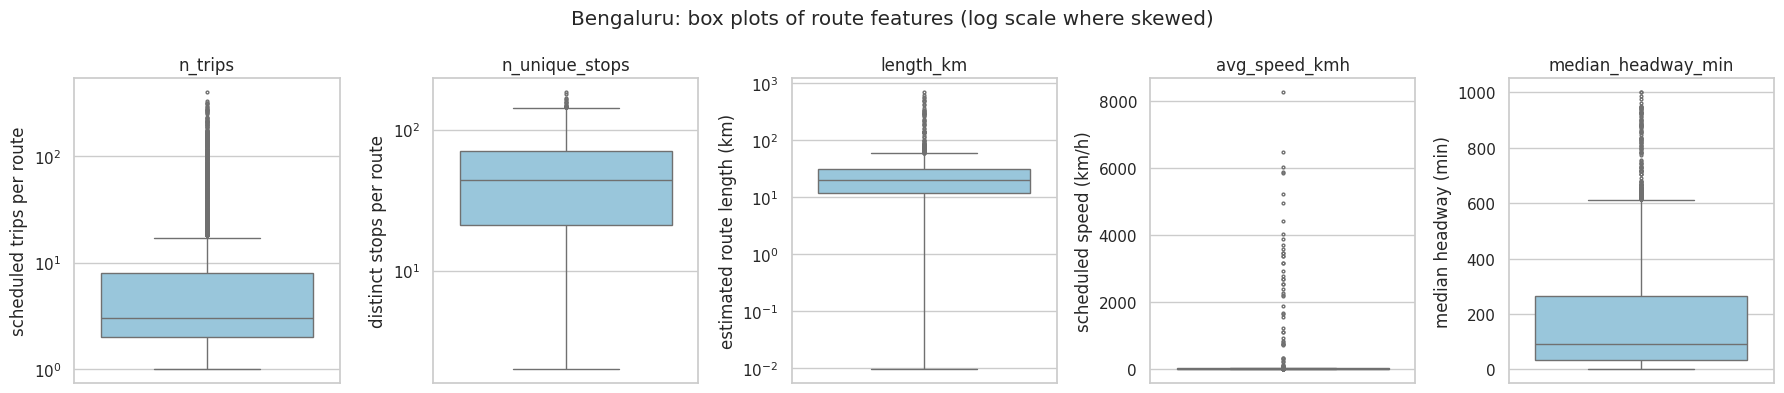

In [36]:
eda.f_outliers(rf, CITY); plt.show()

In [37]:
print("implausible scheduled speed (<3 or >80 km/h):", int(rf.speed_implausible.sum()), "routes")
rf[rf.speed_implausible][["route_name","n_trips","length_km","median_trip_duration_min","avg_speed_kmh","length_method"]].head(8)

implausible scheduled speed (<3 or >80 km/h): 92 routes


,route_name,n_trips,length_km,median_trip_duration_min,avg_speed_kmh,length_method
68,D7-KBS,170,0.134119,5.0,1.609423,stop coordinates (shape failed sanity check)
74,D16-DPJN,111,0.025463,1.0,0.509262,shapes.txt
75,D31-D31G,127,0.084550,1.0,1.690991,stop coordinates (shape failed sanity check)
77,D35-D35G,145,0.009484,1.0,0.189672,stop coordinates (shape failed sanity check)
83,D37-KGR,135,0.098015,1.0,1.960305,stop coordinates (shape failed sanity check)
129,D11-PTH,134,0.097249,1.0,1.944983,stop coordinates (shape failed sanity check)
197,D21-BEML5,152,0.103591,1.0,2.071825,shapes.txt
201,D36-D36G,127,0.063596,1.0,1.271915,shapes.txt


**Reading the table:** a very long route whose scheduled speed is plausible is *valid but unusual* (e.g. an intercity service); a route whose length and duration contradict each other is *suspect*; and some patterns are *source limitations* (e.g. a feed that records vehicle duties as trips). Flagged rows stay in the data (columns `speed_implausible`, `sparse_schedule`). The original GTFS files remain untouched in `data/raw/`; no corrections or exclusions were applied in this module.

## 10. Findings and limitations

In [38]:
print("What this analysis supports:")
for x in eda.obs_univariate(rf)[:2] + eda.obs_hourly(h, p)[:1]: print(" •", x)
print()
print("What it does NOT support: passenger demand, crowding, load factors, or any 'overcrowded' / 'underutilised' verdict; and whether overlapping routes should be merged.")

What this analysis supports:
 • 4,416 routes in the dataset. Scheduled trips per route: median 3, mean 13.1, maximum 398 (133 times the median). 66% of routes have 5 or fewer scheduled trips and 7% have 50 or more, so service levels differ widely between routes.
 • Distinct stops per route: median 44 (range 2-184).
 • Hours with the most scheduled trip starts: 08:00 (4,504), 07:00 (4,115), 15:00 (4,029). Hours with the fewest: 02:00 (31), 00:00 (43), 01:00 (44).

What it does NOT support: passenger demand, crowding, load factors, or any 'overcrowded' / 'underutilised' verdict; and whether overlapping routes should be merged.


**Limitations**
* Scheduled data only – no ridership, occupancy or delays.
* `n_trips` adds up all service patterns of a feed; calendar exceptions (`calendar_dates.txt`) are not applied.
* Lengths from stop coordinates are lower bounds; shapes are used where available.
* Several feeds are community-compiled or old (Delhi/Kochi calendars 2022–24) and some show signs of generated timetables (Delhi, Kochi, Pune) or duty-level trips (Hyderabad).
* Only 7 cities: the Lepton/Datarade dataset is paid and unavailable.

**Next module:** data preprocessing – decide with the mentor how to treat flagged rows and non-comparable feeds, and whether a real ridership source can be obtained.